### Imports and Device Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
from torch import nn


device = torch.accelerator.current_accelerator().type if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


### Load CIFAR10 Dataset

In [ ]:
train_data = datasets.CIFAR10 (
    root='data',
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float, scale=True)])
)

test_data = datasets.CIFAR10 (
    root='data',
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float, scale=True)])
)

100%|██████████| 170M/170M [00:13<00:00, 12.9MB/s]


### DataLoader Setup and Data Exploration

In [ ]:
train_loader = DataLoader(dataset=train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_data, batch_size=64, shuffle=False)

image, label = next(iter(train_loader))
print(f"Image Shape: {image.shape}\nLabel Shape: {label.shape}")

print(f"Number of classes: {len(train_data.classes)}")

Image Shape: torch.Size([64, 3, 32, 32])
Label Shape: torch.Size([64])
Number of classes: 10


### Define Convolutional Neural Network (CNN) Model

In [ ]:
class MyNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.net = nn.Sequential(
        # ------------ Conv Layer 1 ---------------
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        # ------------ Conv Layer 2 ---------------
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        # ------------ Classifier head ------------
        nn.Flatten(),
        nn.Linear(64*8*8, 128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, 10)
    )

  def forward(self, x):
    logits = self.net(x)
    return logits

model = MyNN().to(device)
print(f"Model Summary:\n{model}")

Model Summary:
MyNN(
  (net): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=4096, out_features=128, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.3, inplace=False)
    (10): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Model Training Loop

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=5e-4)

train_loss_history = []
val_loss_history = []
total_acc = 0.0

for epoch in range(20):
  # ---------------------- Training Section --------------------------
  model.train()
  total_train_loss = 0.0
  for x_batch, y_batch in train_loader:
    x_batch, y_batch = x_batch.to(device), y_batch.to(device)
    preds = model(x_batch)
    train_loss = loss_fn(preds, y_batch)
    total_train_loss += train_loss.item()
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

  current_train_epoch_loss = total_train_loss / len(train_loader)
  train_loss_history.append(current_train_epoch_loss)

  # ---------------------- Testing Section ---------------------------
  model.eval()
  correct = 0.0
  with torch.no_grad():
    total_test_loss = 0.0
    for x_batch, y_batch in test_loader:
      x_batch, y_batch = x_batch.to(device), y_batch.to(device)
      preds = model(x_batch)
      test_loss = loss_fn(preds, y_batch)
      total_test_loss += test_loss.item()
      correct += (preds.argmax(1) == y_batch).type(torch.float).sum().item()

  current_val_epoch_loss = total_test_loss / len(test_loader)
  val_loss_history.append(current_val_epoch_loss)
  total_acc += correct / len(test_data) * 100

  print(f"Epoch {epoch + 1}: train loss = {current_train_epoch_loss}, val loss = {current_val_epoch_loss}")

print(f"avg. train loss: {sum(train_loss_history) / len(train_loss_history)}")
print(f"avg. val loss: {sum(val_loss_history) / len(val_loss_history)}")
print(f"avg. accuracy: {total_acc / 20:.4f}%")

Epoch 1: train loss = 1.6708253149486259, val loss = 1.3687763441899778
Epoch 2: train loss = 1.3856310670638023, val loss = 1.2290851595295462
Epoch 3: train loss = 1.2676905421039941, val loss = 1.1602666005966769
Epoch 4: train loss = 1.1790597000542808, val loss = 1.0889031017661854
Epoch 5: train loss = 1.0964770673790856, val loss = 1.0101077127608524
Epoch 6: train loss = 1.0383447393431993, val loss = 0.9787654793186552
Epoch 7: train loss = 0.9863245429285347, val loss = 0.9481216247674007
Epoch 8: train loss = 0.945155963339769, val loss = 0.9238264807470286
Epoch 9: train loss = 0.9064157648617045, val loss = 0.9293659629335829
Epoch 10: train loss = 0.8726087595190843, val loss = 0.869467608108642
Epoch 11: train loss = 0.8421550204839243, val loss = 0.8592436233903192
Epoch 12: train loss = 0.806924853254767, val loss = 0.8825384583442833
Epoch 13: train loss = 0.7809608358785015, val loss = 0.8843051449508424
Epoch 14: train loss = 0.7546021492432451, val loss = 0.8679309

### Visualize Training and Validation Loss

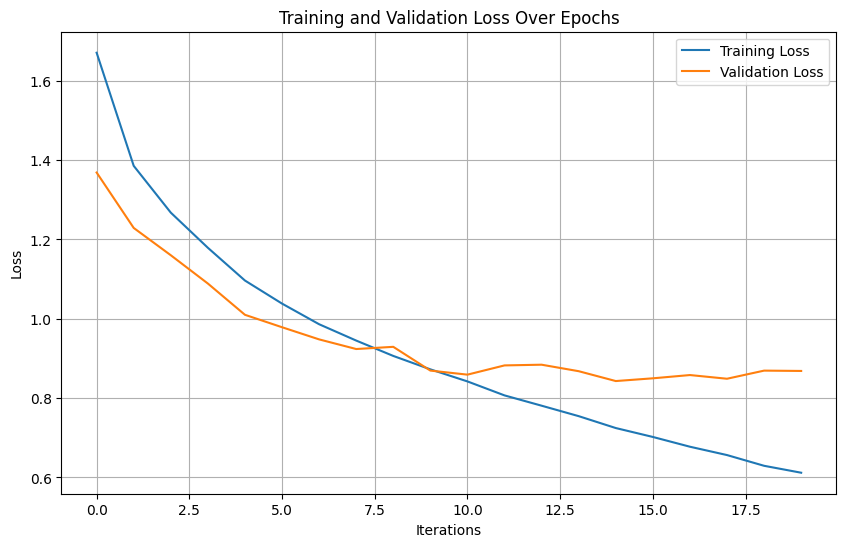

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(train_loss_history, label='Training Loss')
plt.plot(val_loss_history, label='Validation Loss')
plt.title('Training and Validation Loss Over Epochs')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Sample Predictions

In [ ]:
random_indices = np.random.choice(len(test_data), 10, replace=False)

sample_images = []
actual_labels = []

for i in random_indices:
  image, label = test_data[i]
  sample_images.append(image)
  actual_labels.append(label)

input_batch = torch.stack(sample_images).to(device)

model.eval()
with torch.no_grad():
  logits = model(input_batch)
  probablities = torch.nn.functional.softmax(logits, dim=1)
  predicted_labels = torch.argmax(probablities, dim=1)

class_names = test_data.classes
actual_class_names = [class_names[label] for label in actual_labels]
predicted_class_names = [class_names[label] for label in predicted_labels]

print(f"Actual Labels: {actual_class_names}")
print(f"Predicted Labels: {predicted_class_names}")

Actual Labels: ['frog', 'automobile', 'deer', 'airplane', 'automobile', 'frog', 'airplane', 'deer', 'horse', 'automobile']
Predicted Labels: ['frog', 'automobile', 'frog', 'airplane', 'automobile', 'frog', 'airplane', 'bird', 'deer', 'ship']


### Visualize Sample Predictions

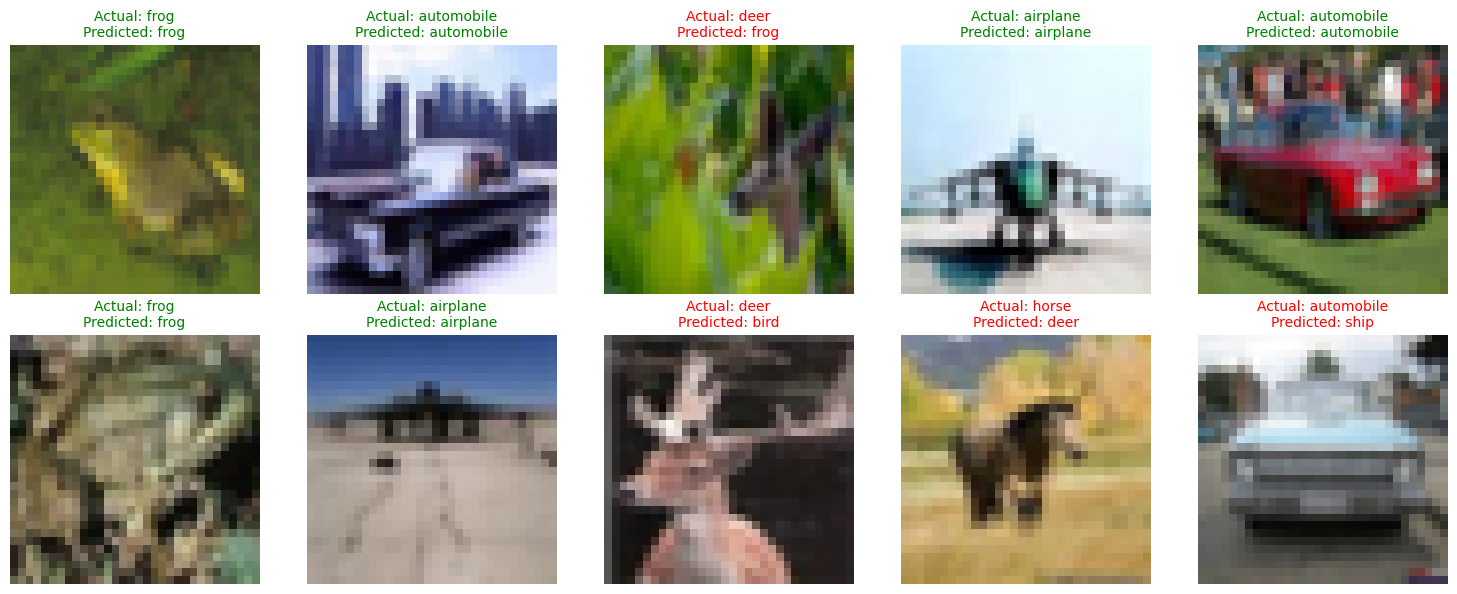

In [ ]:
fig = plt.figure(figsize=(15, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1) # Arrange plots in 2 rows, 5 columns
    plt.imshow(sample_images[i].permute(1, 2, 0).cpu().numpy()) # Transpose dimensions for imshow
    color = "green" if actual_class_names[i] == predicted_class_names[i] else "red"
    plt.title(f"Actual: {actual_class_names[i]}\nPredicted: {predicted_class_names[i]}", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

### Save Trained Model

In [ ]:
torch.save(model.state_dict(), "data/model.pth")
print("Model with their parameters saved successfully!")

Model with their parameters saved successfully!
